# Comparative Machine Learning Methods for Phishing URL Detection

## MSc Business Analytics Dissertation

This notebook presents the Python implementation of a comparative
analysis of four supervised machine learning algorithms for phishing
URL detection.

The algorithms examined are:

- Logistic Regression
- Decision Tree
- Random Forest
- Linear Support Vector Machine (SVM)

The analysis uses the URL-Phish dataset introduced by Linh and Hung
(2025).

The research evaluates classification performance and investigates
the relative importance of numerical URL-based features.

The analytical workflow includes data quality assessment,
feature selection, stratified partitioning, model training,
validation, feature importance analysis and final test evaluation.

In [75]:
#Data manupulation and numerical operations
import pandas as pd
import numpy as np

#Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

import random
#Data splitting and prepocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

#Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

#Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [115]:
# Load dataset
# Download the URL-Phish dataset and place Dataset.csv
# in the same directory as this notebook.

df = pd.read_csv("Dataset.csv")


## 1. Dataset Loading and Initial Exploration

The dataset was loaded into Python using pandas.

Initial exploration examined dataset dimensions, variable types,
column names and descriptive statistics to understand the
structure of the available observations.

In [116]:
df.shape
df.info()
df.columns
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116600 entries, 0 to 116599
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   url           116600 non-null  object 
 1   url_len       116600 non-null  int64  
 2   dom           116600 non-null  object 
 3   dom_len       116600 non-null  int64  
 4   is_ip         116600 non-null  int64  
 5   tld           116586 non-null  object 
 6   tld_len       116600 non-null  int64  
 7   subdom_cnt    116600 non-null  int64  
 8   letter_cnt    116600 non-null  int64  
 9   digit_cnt     116600 non-null  int64  
 10  special_cnt   116600 non-null  int64  
 11  eq_cnt        116600 non-null  int64  
 12  qm_cnt        116600 non-null  int64  
 13  amp_cnt       116600 non-null  int64  
 14  dot_cnt       116600 non-null  int64  
 15  dash_cnt      116600 non-null  int64  
 16  under_cnt     116600 non-null  int64  
 17  letter_ratio  116600 non-null  float64
 18  digi

,url_len,dom_len,is_ip,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,amp_cnt,dot_cnt,dash_cnt,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len,label
count,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.00000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.00000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000,116600.000000
mean,32.952521,12.845763,0.000111,3.320223,0.845669,25.00681,0.943988,7.001724,0.079537,0.038379,0.040866,2.148988,0.34169,0.053799,0.752510,0.013126,0.234364,0.431141,3.215026,3.863736,6.391381,1.600575,0.142367
std,29.369989,5.140745,0.010558,1.418215,0.480620,22.39638,5.947690,3.995755,0.492609,0.199942,0.359917,0.750565,0.97824,0.483712,0.059062,0.047709,0.052906,0.495238,0.930527,0.359595,17.589086,19.273675,0.349428
min,12.000000,4.000000,0.000000,0.000000,0.000000,4.00000,0.000000,4.000000,0.000000,0.000000,0.000000,1.000000,0.00000,0.000000,0.144928,0.000000,0.012998,0.000000,2.000000,2.653544,0.000000,0.000000,0.000000
25%,22.000000,9.000000,0.000000,2.000000,1.000000,16.00000,0.000000,6.000000,0.000000,0.000000,0.000000,2.000000,0.00000,0.000000,0.714286,0.000000,0.194444,0.000000,3.000000,3.642490,1.000000,0.000000,0.000000
50%,27.000000,11.000000,0.000000,3.000000,1.000000,20.00000,0.000000,6.000000,0.000000,0.000000,0.000000,2.000000,0.00000,0.000000,0.750000,0.000000,0.236842,0.000000,3.000000,3.831402,1.000000,0.000000,0.000000
75%,34.000000,16.000000,0.000000,3.000000,1.000000,27.00000,0.000000,7.000000,0.000000,0.000000,0.000000,3.000000,0.00000,0.000000,0.793103,0.000000,0.272727,1.000000,3.000000,4.027169,4.000000,0.000000,0.000000
max,1202.000000,62.000000,1.000000,22.000000,7.000000,1037.00000,321.000000,234.000000,29.000000,17.000000,27.000000,15.000000,25.00000,20.000000,0.936000,0.826087,0.523810,1.000000,37.000000,6.032729,670.000000,1148.000000,1.000000


## 2. Data Quality Assessment and Cleaning

Data quality assessment was conducted to identify missing values,
duplicate observations and potential inconsistencies.

These checks were necessary to establish a reliable analytical
dataset before feature selection and machine learning model
development.

In [78]:
print("Dataset shape:", df.shape)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nRows containing at least one missing value:")
print(df.isnull().any(axis=1).sum())

Dataset shape: (116600, 26)

Missing values per column:
url              0
url_len          0
dom              0
dom_len          0
is_ip            0
tld             14
tld_len          0
subdom_cnt       0
letter_cnt       0
digit_cnt        0
special_cnt      0
eq_cnt           0
qm_cnt           0
amp_cnt          0
dot_cnt          0
dash_cnt         0
under_cnt        0
letter_ratio     0
digit_ratio      0
spec_ratio       0
is_https         0
slash_cnt        0
entropy          0
path_len         0
query_len        0
label            0
dtype: int64

Total missing values:
14

Rows containing at least one missing value:
14


In [79]:
df = df.dropna().copy()

print("Dataset shape after removing missing values:", df.shape)

print("Remaining missing values:", df.isnull().sum().sum())

Dataset shape after removing missing values: (116586, 26)
Remaining missing values: 0


In [80]:
# Check duplicate observations
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Duplicate complete rows:", df.duplicated().sum())

# Check target class distribution
print("\nClass distribution:")
print(df["label"].value_counts().sort_index())

# Check class percentages
print("\nClass percentages:")
print(
    (df["label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Calculate imbalance ratio
class_counts = df["label"].value_counts()

print("\nImbalance ratio:")
print(round(class_counts.max() / class_counts.min(), 2), ": 1")

Duplicate URLs: 1369
Duplicate complete rows: 1369

Class distribution:
label
0    99993
1    16593
Name: count, dtype: int64

Class percentages:
label
0    85.77
1    14.23
Name: proportion, dtype: float64

Imbalance ratio:
6.03 : 1


### 2.1 Duplicate Assessment and Class Distribution

Duplicate observations were examined at both the URL level and
the complete-row level to assess potential data redundancy.

The target class distribution was also examined to identify
class imbalance before model development.

The imbalance ratio was calculated to quantify the relative
representation of the majority and minority classes.

In [81]:
# Remove duplicate complete observations
df = df.drop_duplicates().copy()

# Verify the cleaned dataset
print("Cleaned dataset shape:", df.shape)
print("Remaining duplicate URLs:", df["url"].duplicated().sum())
print("Remaining duplicate complete rows:", df.duplicated().sum())
print("Remaining missing values:", df.isnull().sum().sum())

Cleaned dataset shape: (115217, 26)
Remaining duplicate URLs: 0
Remaining duplicate complete rows: 0
Remaining missing values: 0


In [82]:
# Final class distribution after data cleaning
print("Final class distribution:")
print(df["label"].value_counts().sort_index())

print("\nFinal class percentages:")
print(
    (df["label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Final imbalance ratio
class_counts = df["label"].value_counts()

print("\nFinal imbalance ratio:")
print(round(class_counts.max() / class_counts.min(), 2), ": 1")

Final class distribution:
label
0    98634
1    16583
Name: count, dtype: int64

Final class percentages:
label
0    85.61
1    14.39
Name: proportion, dtype: float64

Final imbalance ratio:
5.95 : 1


### 2.2 Data Cleaning Results

The initial data quality assessment identified 1,369 duplicate
observations. These duplicates were removed to reduce data
redundancy and prevent identical observations from appearing
across training, validation and test partitions.

Following data cleaning, the analytical dataset contained
115,217 observations and 26 columns, with no remaining
missing values or duplicate complete rows.

The class distribution indicated an imbalance between the
majority and minority classes, with approximately 85.61%
and 14.39% of observations, respectively.

This imbalance informed the subsequent application of
balanced class weights during model training.

## 3. Feature Selection and Exploratory Analysis

The initial predictor set contained 22 numerical URL-based
characteristics.

Feature assessment examined missing and infinite values,
constant predictors, correlations and multicollinearity.

The purpose was to identify unsuitable or redundant variables
while retaining features relevant to phishing URL classification.

The final analytical dataset contained 17 numerical predictors.

In [83]:
# Identify numerical and categorical columns

print("Numerical columns:")
print(df.select_dtypes(include=["number"]).columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include=["object"]).columns.tolist())

print("\nDataset dimensions:")
print(df.shape)

Numerical columns:
['url_len', 'dom_len', 'is_ip', 'tld_len', 'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt', 'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len', 'label']

Categorical columns:
['url', 'dom', 'tld']

Dataset dimensions:
(115217, 26)


In [84]:


# Define the 22 numerical predictors
feature_columns = [
    'url_len',
    'dom_len',
    'is_ip',
    'tld_len',
    'subdom_cnt',
    'letter_cnt',
    'digit_cnt',
    'special_cnt',
    'eq_cnt',
    'qm_cnt',
    'amp_cnt',
    'dot_cnt',
    'dash_cnt',
    'under_cnt',
    'letter_ratio',
    'digit_ratio',
    'spec_ratio',
    'is_https',
    'slash_cnt',
    'entropy',
    'path_len',
    'query_len'
]

# Separate predictors (X) and target (y)
X = df[feature_columns].copy()
y = df['label'].copy()

# Display the results
print("Predictor matrix (X):", X.shape)
print("Target variable (y):", y.shape)

print("\nNumber of predictors:", len(feature_columns))

print("\nPredictor columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Predictor matrix (X): (115217, 22)
Target variable (y): (115217,)

Number of predictors: 22

Predictor columns:
['url_len', 'dom_len', 'is_ip', 'tld_len', 'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt', 'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len']

Target distribution:
label
0    98634
1    16583
Name: count, dtype: int64


In [85]:
# Check missing values
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

# Check infinite values
print("Infinite values in X:", np.isinf(X).sum().sum())

# Check data types
print("\nPredictor data types:")
print(X.dtypes.value_counts())

# Check constant features
constant_features = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("\nConstant features:", constant_features)

Missing values in X: 0
Missing values in y: 0
Infinite values in X: 0

Predictor data types:
int64      18
float64     4
Name: count, dtype: int64

Constant features: ['is_ip']


In [86]:
# Examine the constant feature
print("Unique values in is_ip:")
print(df["is_ip"].unique())

print("\nFrequency of each value:")
print(df["is_ip"].value_counts(dropna=False))

print("\nDistribution by target class:")
print(pd.crosstab(df["is_ip"], df["label"]))

Unique values in is_ip:
[0]

Frequency of each value:
is_ip
0    115217
Name: count, dtype: int64

Distribution by target class:
label      0      1
is_ip              
0      98634  16583


In [87]:
# Remove the constant feature from the modelling predictors
X = X.drop(columns=["is_ip"])

print("Updated predictor matrix:", X.shape)
print("Remaining predictors:", X.shape[1])

Updated predictor matrix: (115217, 21)
Remaining predictors: 21


In [88]:
print("Current X shape:", X.shape)
print("\nCurrent columns:")
print(X.columns.tolist())

print("\nis_ip still present:", "is_ip" in X.columns)

Current X shape: (115217, 21)

Current columns:
['url_len', 'dom_len', 'tld_len', 'subdom_cnt', 'letter_cnt', 'digit_cnt', 'special_cnt', 'eq_cnt', 'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'spec_ratio', 'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len']

is_ip still present: False


### 3.1 Constant Feature Assessment

The `is_ip` predictor was examined for variability.

The analysis identified that this feature was constant
within the analytical dataset.

Because a constant predictor provides no variation for
classification, it was excluded from the modelling
feature set.

In [89]:
# Descriptive statistics for the 21 predictors
pd.set_option("display.max_columns", None)

display(X.describe().round(3))

,url_len,dom_len,tld_len,subdom_cnt,letter_cnt,digit_cnt,special_cnt,eq_cnt,qm_cnt,amp_cnt,dot_cnt,dash_cnt,under_cnt,letter_ratio,digit_ratio,spec_ratio,is_https,slash_cnt,entropy,path_len,query_len
count,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000,115217.000
mean,33.020,12.854,3.322,0.845,25.058,0.953,7.009,0.080,0.039,0.041,2.150,0.344,0.054,0.753,0.013,0.234,0.431,3.216,3.865,6.426,1.617
std,29.524,5.149,1.422,0.482,22.510,5.981,4.017,0.495,0.201,0.362,0.753,0.982,0.486,0.059,0.048,0.053,0.495,0.934,0.361,17.673,19.387
min,12.000,4.000,2.000,0.000,6.000,0.000,4.000,0.000,0.000,0.000,1.000,0.000,0.000,0.145,0.000,0.013,0.000,2.000,2.654,0.000,0.000
25%,22.000,9.000,2.000,1.000,16.000,0.000,6.000,0.000,0.000,0.000,2.000,0.000,0.000,0.714,0.000,0.194,0.000,3.000,3.642,1.000,0.000
50%,27.000,11.000,3.000,1.000,20.000,0.000,6.000,0.000,0.000,0.000,2.000,0.000,0.000,0.750,0.000,0.235,0.000,3.000,3.831,1.000,0.000
75%,34.000,16.000,3.000,1.000,27.000,0.000,7.000,0.000,0.000,0.000,3.000,0.000,0.000,0.793,0.000,0.273,1.000,3.000,4.028,4.000,0.000
max,1202.000,62.000,22.000,7.000,1037.000,321.000,234.000,29.000,17.000,27.000,15.000,25.000,20.000,0.936,0.826,0.524,1.000,37.000,6.033,670.000,1148.000


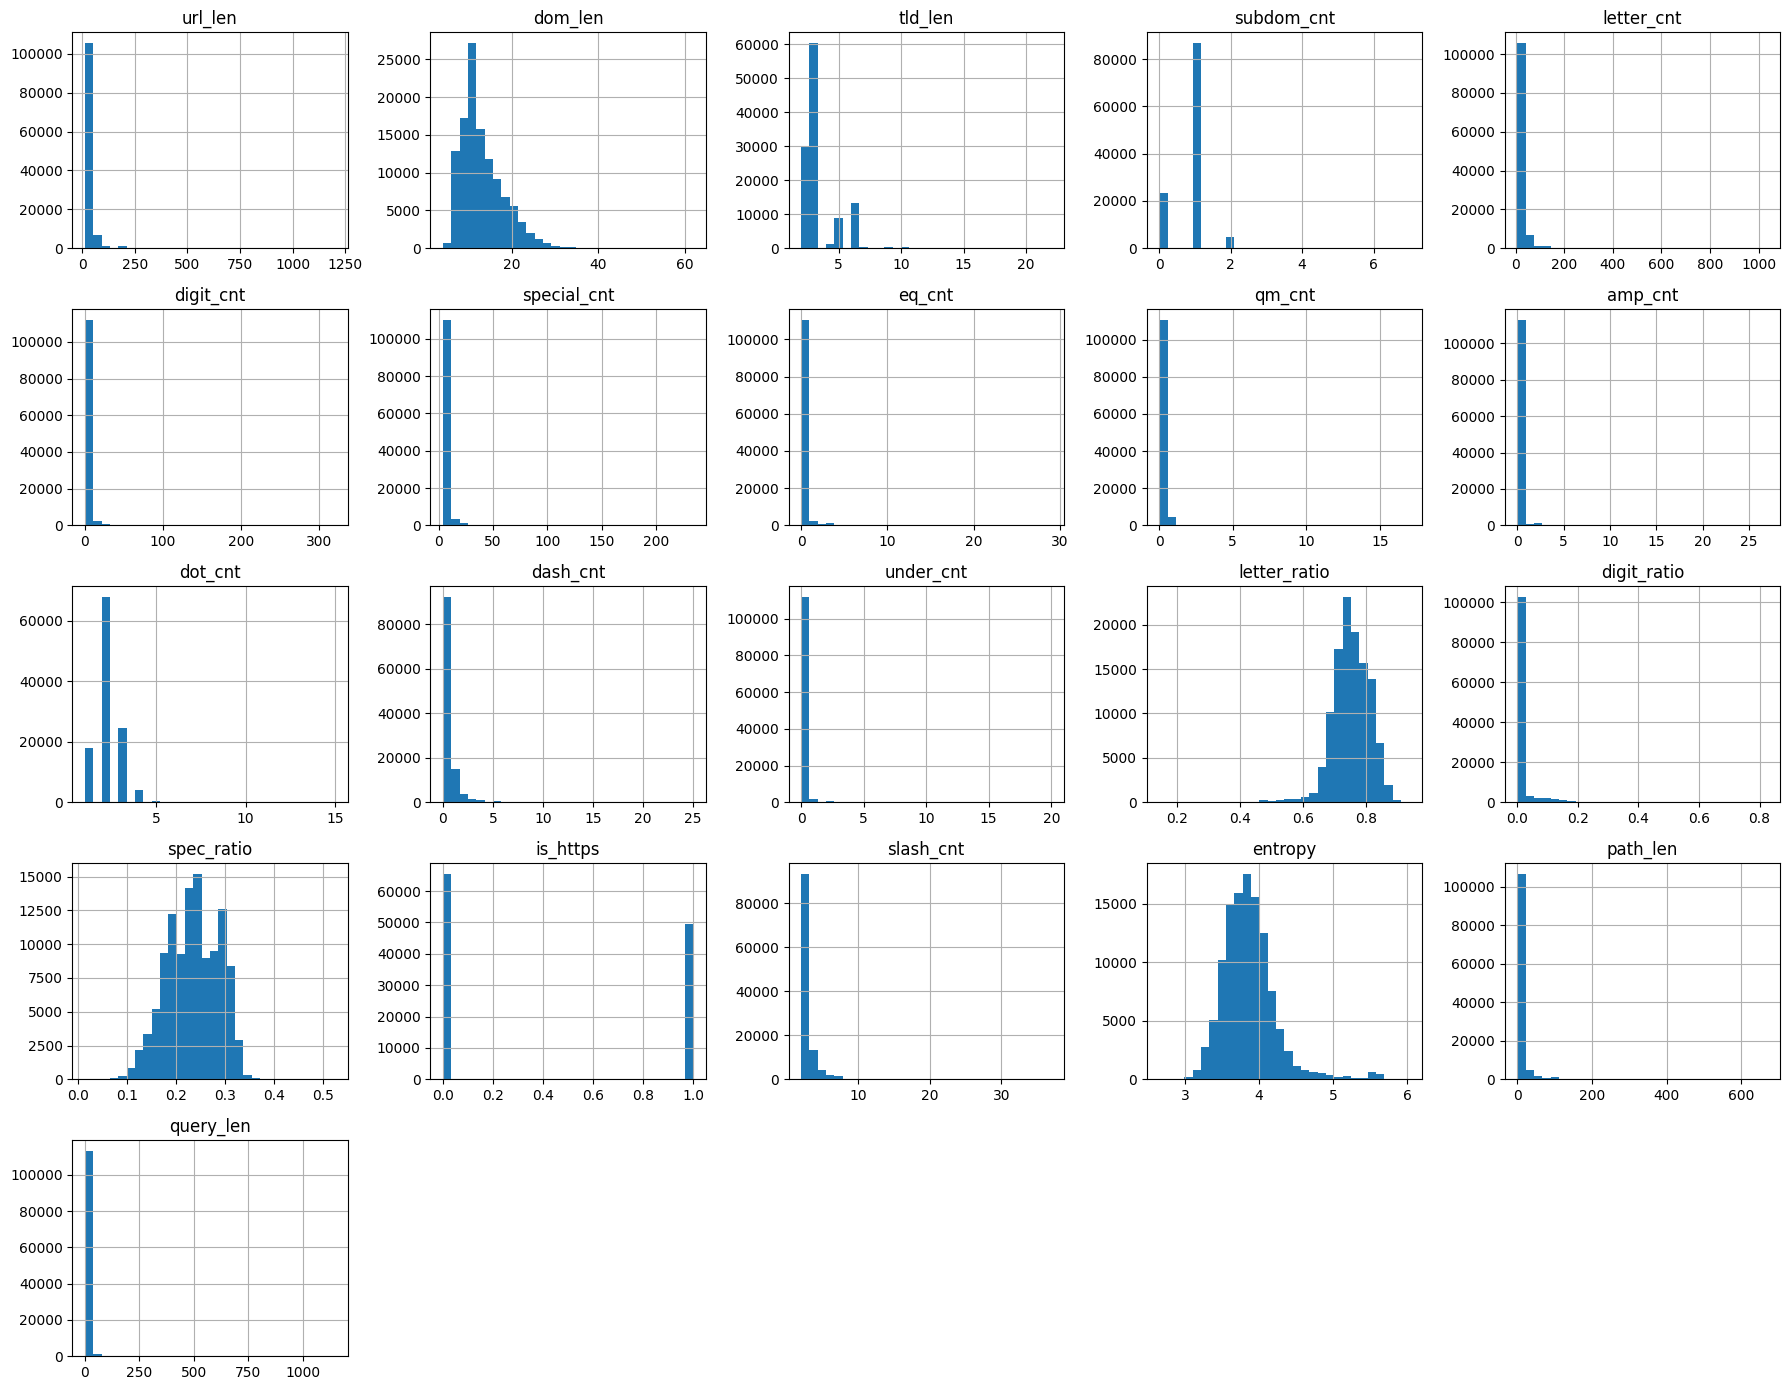

In [90]:
import matplotlib.pyplot as plt

# Histograms of all 21 numerical predictors
X.hist(figsize=(18, 14), bins=30)

plt.tight_layout()
plt.show()

In [91]:
# Calculate potential outliers using the IQR method
outlier_summary = []

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Potential outliers": outliers,
        "Percentage (%)": round(outliers / len(X) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.sort_values(
    by="Potential outliers",
    ascending=False
))

,Feature,Potential outliers,Percentage (%)
17,slash_cnt,33900,29.42
3,subdom_cnt,28268,24.53
2,tld_len,23537,20.43
11,dash_cnt,22740,19.74
19,path_len,20592,17.87
6,special_cnt,16334,14.18
14,digit_ratio,13762,11.94
5,digit_cnt,13762,11.94
0,url_len,9168,7.96
4,letter_cnt,7746,6.72


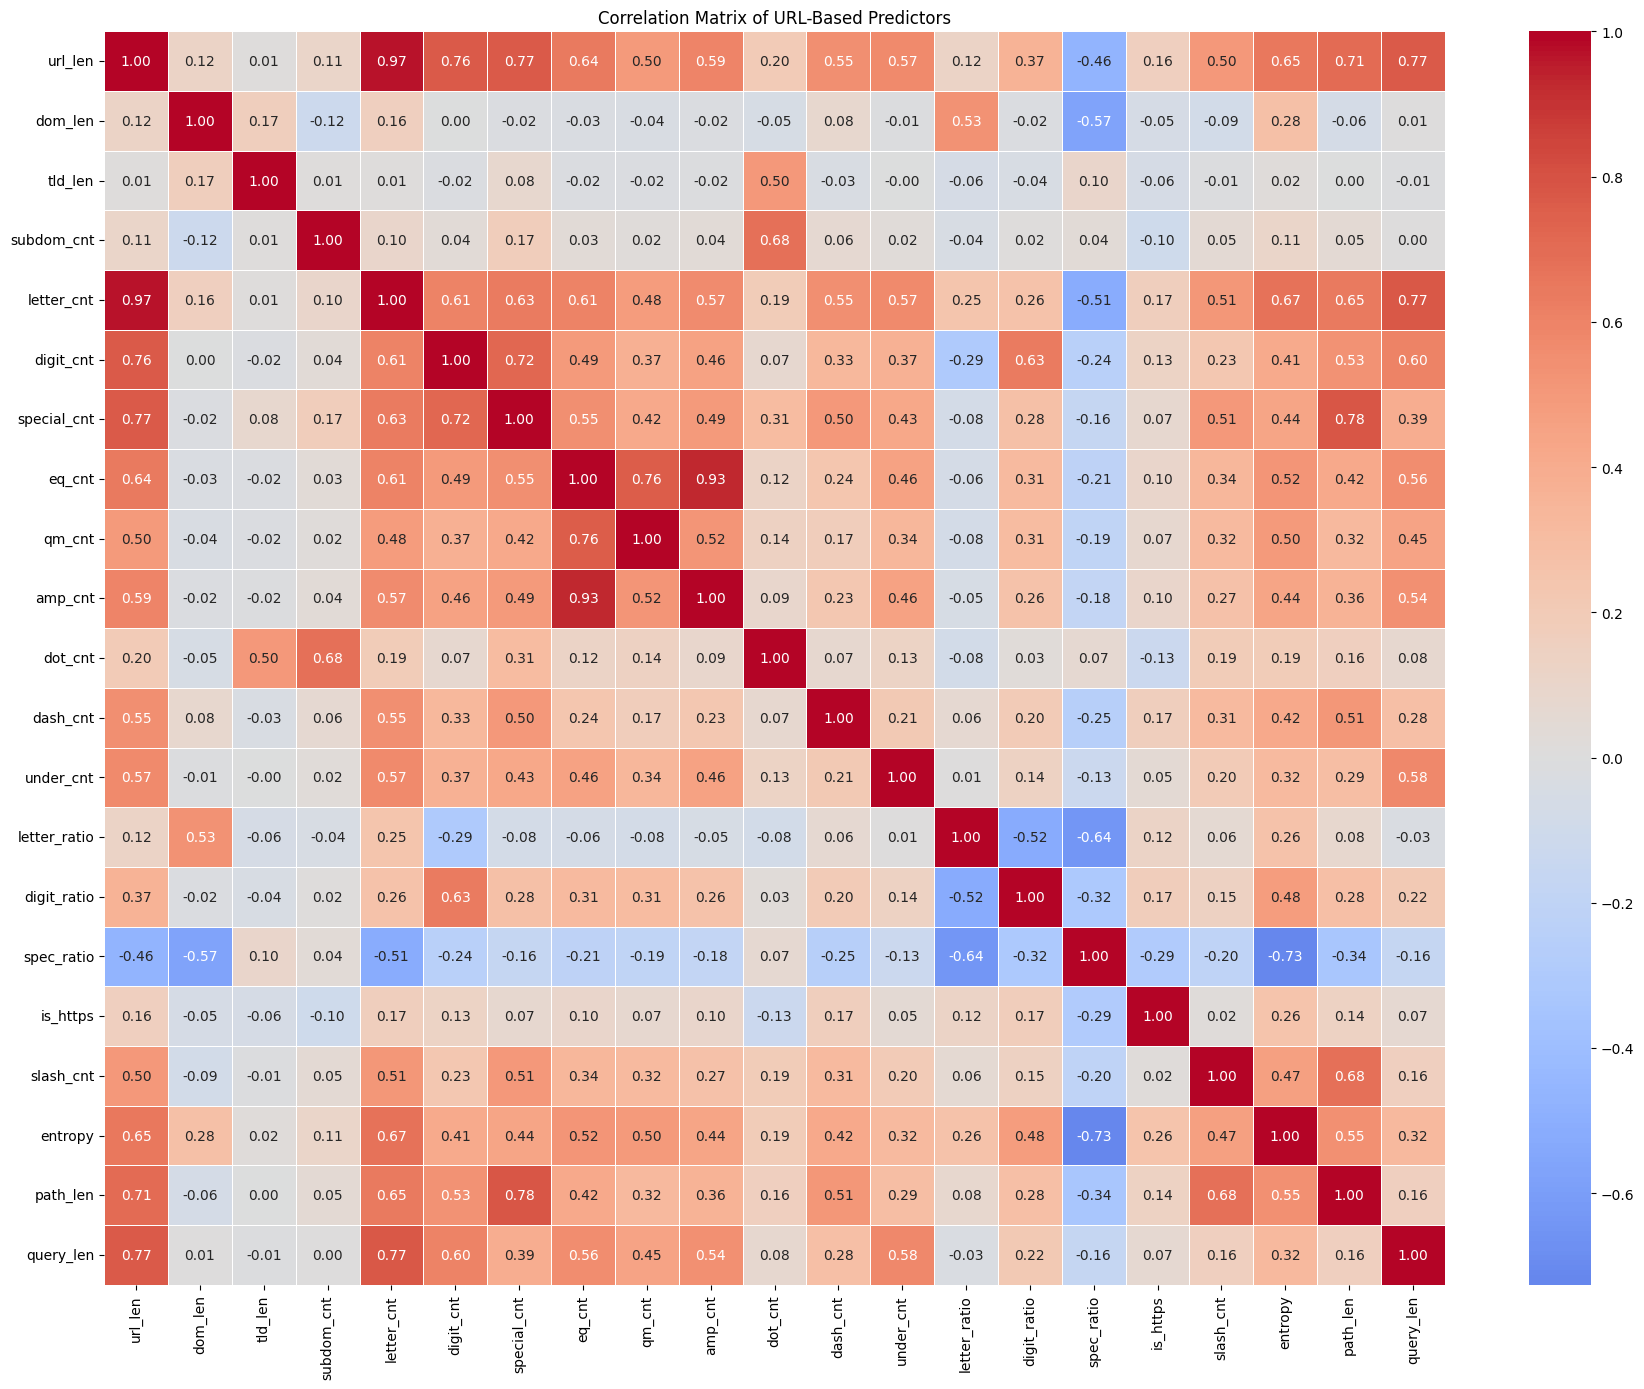

In [92]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate Pearson correlation matrix
correlation_matrix = X.corr(method="pearson")

# Visualise correlations
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of URL-Based Predictors")
plt.tight_layout()
plt.show()

In [93]:
# Extract upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Identify pairs with absolute correlation above 0.80
high_correlations = (
    upper_triangle.stack()
    .reset_index()
)

high_correlations.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

high_correlations = high_correlations[
    high_correlations["Correlation"].abs() > 0.80
].sort_values(
    by="Correlation",
    key=abs,
    ascending=False
)

display(high_correlations)

,Feature 1,Feature 2,Correlation
3,url_len,letter_cnt,0.971985
120,eq_cnt,amp_cnt,0.927993


In [94]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Add a constant for VIF calculation
X_vif = add_constant(X)

# Calculate VIF for each predictor
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Exclude the intercept
vif_data = vif_data[vif_data["Feature"] != "const"]

# Sort results
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(3))

C:\Users\U S E R\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


,Feature,VIF
6,digit_cnt,2.370316e+14
7,special_cnt,7.764827e+13
5,letter_cnt,3.546141e+13
1,url_len,8.847936e+12
15,digit_ratio,2.677988e+08
16,spec_ratio,1.443756e+04
14,letter_ratio,6.443729e+03
8,eq_cnt,3.221300e+01
21,query_len,2.306000e+01
10,amp_cnt,1.835200e+01


In [95]:
# Investigate whether URL length equals the sum of character counts

df["calculated_url_len"] = (
    df["letter_cnt"] +
    df["digit_cnt"] +
    df["special_cnt"]
)

print(
    "Rows where calculated length equals url_len:",
    (df["calculated_url_len"] == df["url_len"]).sum()
)

print(
    "Total observations:",
    len(df)
)

# Investigate character ratios
print("\nChecking character ratios:")

print(
    "digit_ratio equals digit_cnt / url_len:",
    np.allclose(
        df["digit_ratio"],
        df["digit_cnt"] / df["url_len"]
    )
)

print(
    "letter_ratio equals letter_cnt / url_len:",
    np.allclose(
        df["letter_ratio"],
        df["letter_cnt"] / df["url_len"]
    )
)

print(
    "spec_ratio equals special_cnt / url_len:",
    np.allclose(
        df["spec_ratio"],
        df["special_cnt"] / df["url_len"]
    )
)

# Check whether the three ratios sum to one
ratio_sum = (
    df["letter_ratio"] +
    df["digit_ratio"] +
    df["spec_ratio"]
)

print(
    "\nRatio sum equals one:",
    np.allclose(ratio_sum, 1)
)

Rows where calculated length equals url_len: 115217
Total observations: 115217

Checking character ratios:
digit_ratio equals digit_cnt / url_len: True
letter_ratio equals letter_cnt / url_len: True
spec_ratio equals special_cnt / url_len: True

Ratio sum equals one: True


In [96]:
# Remove mathematically redundant features

redundant_features = ["special_cnt", "spec_ratio"]

X = X.drop(columns=redundant_features)

# Remove the temporary diagnostic column from df
df.drop(columns=["calculated_url_len"], inplace=True, errors="ignore")

print("Updated feature matrix shape:", X.shape)
print("\nRemaining features:")
print(X.columns.tolist())

Updated feature matrix shape: (115217, 19)

Remaining features:
['url_len', 'dom_len', 'tld_len', 'subdom_cnt', 'letter_cnt', 'digit_cnt', 'eq_cnt', 'qm_cnt', 'amp_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len']


In [97]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Add a constant for the VIF calculation
X_vif = sm.add_constant(X)

# Calculate VIF for each predictor
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Exclude the constant from the results
vif_data = vif_data[vif_data["Feature"] != "const"]

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

print(vif_data.to_string(index=False))

     Feature        VIF
     url_len 439.499407
  letter_cnt 241.317036
   digit_cnt  41.024922
      eq_cnt  32.209124
   query_len  23.059426
     amp_cnt  18.350638
    path_len  16.261996
letter_ratio   7.303792
 digit_ratio   7.227778
      qm_cnt   6.223103
     entropy   4.941189
     dot_cnt   4.382913
  subdom_cnt   3.103082
     dom_len   2.755268
   slash_cnt   2.559836
     tld_len   2.197847
    dash_cnt   2.197266
   under_cnt   1.877509
    is_https   1.287270


### 3.2 Correlation and Multicollinearity Assessment

Pearson correlation analysis and variance inflation factors
(VIF) were used to investigate relationships between
numerical predictors.

The initial assessment identified strong relationships
and mathematical redundancy among selected URL features.

The variables `special_cnt` and `spec_ratio` were excluded
following the redundancy investigation.

Further analysis supported the exclusion of `letter_cnt`
and `amp_cnt`.

These exclusions reduced the predictor set while limiting
redundancy in the final modelling inputs.

In [98]:
# Examine correlations among the most problematic predictors

selected_features = [
    "url_len",
    "letter_cnt",
    "digit_cnt",
    "letter_ratio",
    "digit_ratio",
    "eq_cnt",
    "amp_cnt",
    "query_len",
    "path_len"
]

correlation_matrix = X[selected_features].corr()

print(correlation_matrix.round(3))

              url_len  letter_cnt  digit_cnt  letter_ratio  digit_ratio  \
url_len         1.000       0.972      0.764         0.120        0.366   
letter_cnt      0.972       1.000      0.608         0.250        0.262   
digit_cnt       0.764       0.608      1.000        -0.295        0.635   
letter_ratio    0.120       0.250     -0.295         1.000       -0.525   
digit_ratio     0.366       0.262      0.635        -0.525        1.000   
eq_cnt          0.638       0.608      0.494        -0.062        0.313   
amp_cnt         0.592       0.566      0.459        -0.046        0.262   
query_len       0.766       0.774      0.605        -0.028        0.216   
path_len        0.708       0.648      0.532         0.079        0.280   

              eq_cnt  amp_cnt  query_len  path_len  
url_len        0.638    0.592      0.766     0.708  
letter_cnt     0.608    0.566      0.774     0.648  
digit_cnt      0.494    0.459      0.605     0.532  
letter_ratio  -0.062   -0.046     -0.

In [99]:
# Create a temporary feature set without the two highly correlated predictors

features_to_remove = ["letter_cnt", "amp_cnt"]

X_revised = X.drop(columns=features_to_remove)

print("Number of observations:", X_revised.shape[0])
print("Number of predictors:", X_revised.shape[1])

# Recalculate VIF
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X_vif_revised = sm.add_constant(X_revised)

vif_revised = pd.DataFrame({
    "Feature": X_vif_revised.columns,
    "VIF": [
        variance_inflation_factor(X_vif_revised.values, i)
        for i in range(X_vif_revised.shape[1])
    ]
})

vif_revised = vif_revised[
    vif_revised["Feature"] != "const"
].sort_values(by="VIF", ascending=False)

print("\nUpdated VIF results:")
print(vif_revised.to_string(index=False))

Number of observations: 115217
Number of predictors: 17

Updated VIF results:
     Feature       VIF
     url_len 63.034522
   query_len 21.266615
    path_len 15.897390
   digit_cnt  7.029329
letter_ratio  6.929405
 digit_ratio  5.830118
     entropy  4.930614
     dot_cnt  4.128072
      eq_cnt  3.260212
  subdom_cnt  3.081857
     dom_len  2.697689
      qm_cnt  2.633286
   slash_cnt  2.513550
     tld_len  2.178560
    dash_cnt  2.060174
   under_cnt  1.789419
    is_https  1.282424


In [100]:
# Finalise the selected predictors
X = X_revised.copy()

# Define the target variable
y = df["label"].copy()

# Verify the final dataset
print("Final feature matrix:", X.shape)
print("Target variable:", y.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nClass distribution (%):")
print((y.value_counts(normalize=True) * 100).round(2))

print("\nMissing values in predictors:", X.isnull().sum().sum())
print("Missing values in target:", y.isnull().sum())

print("\nFinal predictors:")
print(X.columns.tolist())

Final feature matrix: (115217, 17)
Target variable: (115217,)

Class distribution:
label
0    98634
1    16583
Name: count, dtype: int64

Class distribution (%):
label
0    85.61
1    14.39
Name: proportion, dtype: float64

Missing values in predictors: 0
Missing values in target: 0

Final predictors:
['url_len', 'dom_len', 'tld_len', 'subdom_cnt', 'digit_cnt', 'eq_cnt', 'qm_cnt', 'dot_cnt', 'dash_cnt', 'under_cnt', 'letter_ratio', 'digit_ratio', 'is_https', 'slash_cnt', 'entropy', 'path_len', 'query_len']


## 4. Stratified Dataset Partitioning and Preprocessing

The dataset was divided into training, validation and test
subsets using stratified random sampling.

The allocation was:

- Training: 70%
- Validation: 15%
- Testing: 15%

Stratification preserved the approximate class proportions
across the three partitions.

A fixed random seed of 42 was used to support reproducibility.

In [101]:
from sklearn.model_selection import train_test_split

# First split: 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: divide temporary data equally
# Result: 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

# Display the dimensions of each subset
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Testing set:", X_test.shape, y_test.shape)

Training set: (80651, 17) (80651,)
Validation set: (17283, 17) (17283,)
Testing set: (17283, 17) (17283,)


In [102]:
# Check class proportions in each subset

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} set:")
    print(target.value_counts())
    print((target.value_counts(normalize=True) * 100).round(2))


Training set:
label
0    69043
1    11608
Name: count, dtype: int64
label
0    85.61
1    14.39
Name: proportion, dtype: float64

Validation set:
label
0    14795
1     2488
Name: count, dtype: int64
label
0    85.6
1    14.4
Name: proportion, dtype: float64

Testing set:
label
0    14796
1     2487
Name: count, dtype: int64
label
0    85.61
1    14.39
Name: proportion, dtype: float64


### 4.1 Feature Standardisation

StandardScaler was fitted exclusively on the training
dataset to prevent information leakage from validation
and test observations.

The fitted transformation was subsequently applied
to the validation and test predictors.

Standardised features were used for Logistic Regression
and Linear SVM.

Decision Tree and Random Forest were trained using
the original unscaled numerical predictors.

In [103]:
from sklearn.preprocessing import StandardScaler

# Initialise the scaler
scaler = StandardScaler()

# Fit scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and testing data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Check dimensions
print("Scaled training set:", X_train_scaled.shape)
print("Scaled validation set:", X_val_scaled.shape)
print("Scaled testing set:", X_test_scaled.shape)

Scaled training set: (80651, 17)
Scaled validation set: (17283, 17)
Scaled testing set: (17283, 17)


In [104]:
import numpy as np

print("Training feature means (first five):")
print(np.mean(X_train_scaled, axis=0)[:5].round(4))

print("\nTraining feature standard deviations (first five):")
print(np.std(X_train_scaled, axis=0)[:5].round(4))

Training feature means (first five):
[ 0. -0.  0.  0. -0.]

Training feature standard deviations (first five):
[1. 1. 1. 1. 1.]


## 5. Machine Learning Model Training

Four supervised machine learning algorithms were trained
using the same training observations and selected predictors.

The models were:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Linear Support Vector Machine

Balanced class weights were applied to all classifiers
to account for the unequal target class distribution.

Logistic Regression and Linear SVM used standardised
features, whereas Decision Tree and Random Forest
used unscaled predictors.

No systematic hyperparameter optimisation was conducted.

In [105]:
# Import required libraries

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np
import time

# Initialise the four machine learning models

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
}

# Prepare the appropriate training datasets

training_data = {
    "Logistic Regression": (X_train_scaled, y_train),
    "Decision Tree": (X_train, y_train),
    "Random Forest": (X_train, y_train),
    "Linear SVM": (X_train_scaled, y_train)
}

# Train the models

trained_models = {}
training_times = {}

for name, model in models.items():

    X_model_train, y_model_train = training_data[name]

    start_time = time.time()

    model.fit(X_model_train, y_model_train)

    end_time = time.time()

    trained_models[name] = model

    training_times[name] = end_time - start_time

    print(f"{name} trained successfully.")
    print(f"Training time: {training_times[name]:.2f} seconds")
    print("-" * 50)

print("\nAll four models have been trained successfully.")

Logistic Regression trained successfully.
Training time: 0.55 seconds
--------------------------------------------------
Decision Tree trained successfully.
Training time: 0.71 seconds
--------------------------------------------------
Random Forest trained successfully.
Training time: 17.55 seconds
--------------------------------------------------
Linear SVM trained successfully.
Training time: 1.68 seconds
--------------------------------------------------

All four models have been trained successfully.


## 6. Validation Performance Evaluation

The four trained models were evaluated using the
validation dataset.

Six performance metrics were calculated:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Average precision (PR-AUC summary)

Confusion matrices were also generated to examine
true positives, true negatives, false positives
and false negatives.

Average precision was particularly relevant because
the phishing class represented a minority of the dataset.

In [106]:
# Store validation results

validation_results = []

for name, model in trained_models.items():

    # Select the appropriate validation dataset
    if name in ["Logistic Regression", "Linear SVM"]:
        X_model_val = X_val_scaled
    else:
        X_model_val = X_val

    # Generate predictions
    y_pred = model.predict(X_model_val)

    # Generate scores for ROC-AUC and PR-AUC
    if name == "Linear SVM":
        y_scores = model.decision_function(X_model_val)
    else:
        y_scores = model.predict_proba(X_model_val)[:, 1]

    # Calculate evaluation metrics
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred, pos_label=1),
        "Recall": recall_score(y_val, y_pred, pos_label=1),
        "F1-score": f1_score(y_val, y_pred, pos_label=1),
        "ROC-AUC": roc_auc_score(y_val, y_scores),
        "PR-AUC": average_precision_score(y_val, y_scores)
    }

    validation_results.append(results)

# Create results dataframe
validation_df = pd.DataFrame(validation_results)

# Display results
print("VALIDATION SET PERFORMANCE COMPARISON")
display(validation_df.round(4))

VALIDATION SET PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9244,0.6714,0.9297,0.7797,0.9779,0.9048
1,Decision Tree,0.9691,0.8856,0.9019,0.8937,0.9427,0.8299
2,Random Forest,0.9795,0.9376,0.9184,0.9279,0.9898,0.9721
3,Linear SVM,0.9232,0.6677,0.9281,0.7767,0.9775,0.9042


#Validation Findings

Random Forest achieved the strongest overall validation
performance in terms of F1-score, ROC-AUC and average precision.

Logistic Regression and Linear SVM achieved relatively high
recall but lower precision, indicating a greater tendency
to classify legitimate URLs as phishing.

These findings illustrate the operational trade-off between
detecting phishing threats and limiting false alarms.


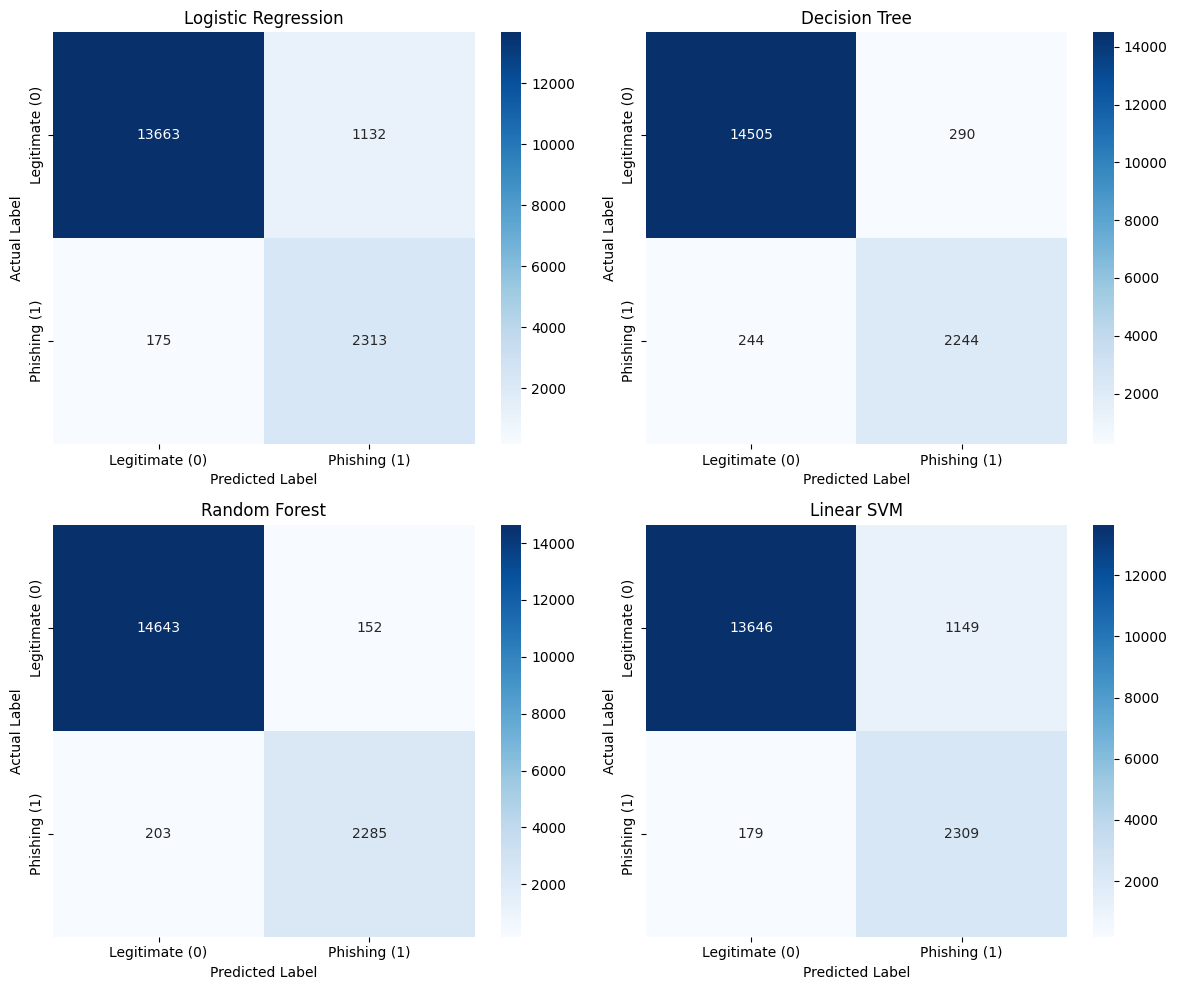

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes = axes.flatten()

for ax, (name, model) in zip(axes, trained_models.items()):

    if name in ["Logistic Regression", "Linear SVM"]:
        X_model_val = X_val_scaled
    else:
        X_model_val = X_val

    y_pred = model.predict(X_model_val)

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate (0)", "Phishing (1)"],
        yticklabels=["Legitimate (0)", "Phishing (1)"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

Based on your matrices, and assuming 0 = legitimate and 1 = phishing, we obtain:

Model	True Negatives (TN)	False Positives (FP)	False Negatives (FN)	True Positives (TP)
Logistic Regression	13,663	1,132	175	2,313
Decision Tree	14,505	290	244	2,244
Random Forest	14,643	152	203	2,285
Linear SVM	13,646	1,149	179	2,309

All four matrices account for 17,283 validation observations.

2. Interpretation of the results
Random Forest

Random Forest produces the strongest overall classification performance.

It correctly identifies:

14,643 legitimate URLs.
2,285 phishing URLs.

Its errors are:

152 legitimate URLs incorrectly classified as phishing.
203 phishing URLs incorrectly classified as legitimate.

The relatively low number of false positives and false negatives indicates a good balance between identifying phishing threats and avoiding unnecessary security alerts.

Logistic Regression

Logistic Regression identifies 2,313 phishing URLs, the highest number among the four models.

However, it incorrectly classifies 1,132 legitimate URLs as phishing.

This could create additional work for cybersecurity teams investigating false alerts.

Decision Tree

Decision Tree correctly identifies 14,505 legitimate URLs but misses 244 phishing URLs.

Its false-positive count (290) is substantially lower than those of Logistic Regression and Linear SVM.

However, its false-negative count is the highest among the four models.

Linear SVM

Linear SVM behaves similarly to Logistic Regression.

It identifies 2,309 phishing URLs but incorrectly classifies 1,149 legitimate URLs as phishing.

This suggests a similar trade-off between phishing detection and false alarms.

3. Comparison from a cybersecurity risk management perspective

An important distinction emerges from these results.

False negatives represent a potential security risk, because phishing URLs may be incorrectly classified as legitimate.

False positives represent an operational risk, because legitimate URLs may be blocked or referred for unnecessary investigation.

Random Forest achieves a particularly attractive balance:

Only 152 false positives.
Only 203 false negatives.

This reinforces its strong validation performance.

However, the preferred model in an organisation would also depend on its risk appetite. An organisation prioritising the avoidance of missed phishing threats might prefer a model with higher recall, even if that produces more false positives.

This distinction will be useful when discussing RQ1.

## 7. Feature Importance Analysis

Feature importance analysis was conducted to investigate
the contribution of numerical URL characteristics to
phishing classification.

Three complementary approaches were used:

1. Model-specific feature importance
2. Permutation feature importance
3. Signed coefficient analysis

The analysis aimed to identify influential URL
characteristics and examine whether feature rankings
were consistent across the four classifiers.

In [108]:
# ==========================================
# FEATURE IMPORTANCE EXTRACTION
# ==========================================

# Create feature importance dataframe

feature_importance = pd.DataFrame({
    "Feature": X_train.columns
})

# Logistic Regression coefficients
lr_importance = np.abs(
    trained_models["Logistic Regression"].coef_[0]
)

feature_importance["Logistic Regression"] = lr_importance

# Decision Tree importance
feature_importance["Decision Tree"] = (
    trained_models["Decision Tree"].feature_importances_
)

# Random Forest importance
feature_importance["Random Forest"] = (
    trained_models["Random Forest"].feature_importances_
)

# Linear SVM coefficients
svm_importance = np.abs(
    trained_models["Linear SVM"].coef_[0]
)

feature_importance["Linear SVM"] = svm_importance

# Sort by Random Forest importance
feature_importance = feature_importance.sort_values(
    by="Random Forest",
    ascending=False
)

# Display results
print("FEATURE IMPORTANCE COMPARISON")

display(feature_importance.round(5))

FEATURE IMPORTANCE COMPARISON


,Feature,Logistic Regression,Decision Tree,Random Forest,Linear SVM
12,is_https,1.29964,0.34801,0.19060,0.38010
14,entropy,1.78750,0.16915,0.14910,0.56496
11,digit_ratio,1.12200,0.04407,0.11374,0.31809
1,dom_len,2.19868,0.07843,0.09463,0.61155
4,digit_cnt,0.68194,0.07980,0.07958,0.21572
0,url_len,9.69014,0.03645,0.07860,2.51458
15,path_len,6.52976,0.07657,0.07242,1.73403
10,letter_ratio,0.28178,0.02852,0.04886,0.10351
8,dash_cnt,0.08910,0.02293,0.03943,0.03452
2,tld_len,0.40858,0.02437,0.03847,0.11425


In [109]:
# ==========================================
# NORMALISED FEATURE IMPORTANCE AND RANKING
# ==========================================

importance_columns = [
    "Logistic Regression",
    "Decision Tree",
    "Random Forest",
    "Linear SVM"
]

# Create a copy of the existing importance dataframe
normalised_importance = feature_importance.copy()

# Normalise each model's importance scores
for model_name in importance_columns:

    total_importance = normalised_importance[model_name].sum()

    normalised_importance[model_name] = (
        normalised_importance[model_name] / total_importance
    )

# Create feature ranking for each model
for model_name in importance_columns:

    normalised_importance[model_name + " Rank"] = (
        normalised_importance[model_name]
        .rank(ascending=False, method="min")
        .astype(int)
    )

# Calculate average feature ranking
rank_columns = [
    model_name + " Rank"
    for model_name in importance_columns
]

normalised_importance["Average Rank"] = (
    normalised_importance[rank_columns].mean(axis=1)
)

# Sort by average ranking
normalised_importance = normalised_importance.sort_values(
    by="Average Rank"
)

# Display results
print("NORMALISED FEATURE IMPORTANCE AND RANKINGS")

display(normalised_importance.round(4))

NORMALISED FEATURE IMPORTANCE AND RANKINGS


,Feature,Logistic Regression,Decision Tree,Random Forest,Linear SVM,Logistic Regression Rank,Decision Tree Rank,Random Forest Rank,Linear SVM Rank,Average Rank
14,entropy,0.0545,0.1691,0.1491,0.0629,5,2,2,5,3.50
0,url_len,0.2956,0.0364,0.0786,0.2799,1,7,6,1,3.75
12,is_https,0.0396,0.3480,0.1906,0.0423,7,1,1,7,4.00
1,dom_len,0.0671,0.0784,0.0946,0.0681,4,4,4,4,4.00
15,path_len,0.1992,0.0766,0.0724,0.1930,2,5,7,2,4.00
11,digit_ratio,0.0342,0.0441,0.1137,0.0354,8,6,3,8,6.25
4,digit_cnt,0.0208,0.0798,0.0796,0.0240,9,3,5,9,6.50
3,subdom_cnt,0.0494,0.0337,0.0266,0.0507,6,8,12,6,8.00
16,query_len,0.1723,0.0022,0.0052,0.1672,3,15,14,3,8.75
10,letter_ratio,0.0086,0.0285,0.0489,0.0115,13,10,8,13,11.00


Finding 1: Entropy

Entropy achieves the strongest average ranking (3.50).

It ranks second in both Decision Tree and Random Forest and fifth in both linear models.

This suggests that URL complexity, as captured by entropy, provides useful information for distinguishing between legitimate and phishing URLs.

Finding 2: URL length

url_len ranks first in both Logistic Regression and Linear SVM.

However, it ranks seventh in Decision Tree and sixth in Random Forest.

This difference suggests that linear and tree-based algorithms capture different patterns in the relationship between URL length and phishing classification.

Finding 3: HTTPS

is_https is the most important feature for both tree-based models.

However, it ranks seventh in the linear models.

This is particularly interesting because it suggests that the importance assigned to HTTPS depends partly on the classification algorithm.

We should also remember that HTTPS does not guarantee website legitimacy.

Finding 4: Domain length

dom_len achieves a ranking of fourth across all four models.

This consistency makes it particularly interesting.

It suggests that domain length contributes relatively stable information to the classification decisions, irrespective of the algorithm used.

Finding 5: Query length

query_len ranks third in both linear models but fourteenth and fifteenth in the tree-based models.

### 7.1 Permutation Feature Importance

Permutation importance was calculated using the
validation dataset.

Each feature was randomly permuted five times,
and the resulting change in average precision
was measured.

This approach provided a complementary assessment
of feature importance based on predictive performance.

The findings were interpreted cautiously because
correlated predictors can influence permutation
importance estimates.

In [110]:
# ==========================================
# PERMUTATION FEATURE IMPORTANCE
# ==========================================

from sklearn.inspection import permutation_importance

permutation_results = {}

for name, model in trained_models.items():

    print(f"Calculating permutation importance: {name}")

    # Select appropriate validation data
    if name in ["Logistic Regression", "Linear SVM"]:
        X_model_val = X_val_scaled
    else:
        X_model_val = X_val

    # Calculate permutation importance
    result = permutation_importance(
        model,
        X_model_val,
        y_val,
        scoring="average_precision",
        n_repeats=5,
        random_state=42,
        n_jobs=1
    )

    permutation_results[name] = result

    print(f"Completed: {name}")
    print("-" * 50)


# Create comparison dataframe

permutation_df = pd.DataFrame({
    "Feature": X_train.columns
})

for name, result in permutation_results.items():

    permutation_df[name] = result.importances_mean

    permutation_df[name + " Std"] = result.importances_std


# Calculate average ranking

for name in trained_models.keys():

    permutation_df[name + " Rank"] = (
        permutation_df[name]
        .rank(ascending=False, method="min")
        .astype(int)
    )


rank_columns = [
    name + " Rank"
    for name in trained_models.keys()
]

permutation_df["Average Rank"] = (
    permutation_df[rank_columns].mean(axis=1)
)

permutation_df = permutation_df.sort_values(
    by="Average Rank"
)

print("\nPERMUTATION FEATURE IMPORTANCE COMPARISON")

display(permutation_df.round(5))

Calculating permutation importance: Logistic Regression
Completed: Logistic Regression
--------------------------------------------------
Calculating permutation importance: Decision Tree
Completed: Decision Tree
--------------------------------------------------
Calculating permutation importance: Random Forest
Completed: Random Forest
--------------------------------------------------
Calculating permutation importance: Linear SVM
Completed: Linear SVM
--------------------------------------------------

PERMUTATION FEATURE IMPORTANCE COMPARISON


,Feature,Logistic Regression,Logistic Regression Std,Decision Tree,Decision Tree Std,Random Forest,Random Forest Std,Linear SVM,Linear SVM Std,Logistic Regression Rank,Decision Tree Rank,Random Forest Rank,Linear SVM Rank,Average Rank
0,url_len,0.66090,0.00269,0.32772,0.00643,0.02614,0.00193,0.63771,0.00266,1,2,5,1,2.25
1,dom_len,0.22926,0.00397,0.34443,0.00225,0.15354,0.00597,0.21625,0.00383,4,1,1,4,2.50
15,path_len,0.28562,0.00259,0.28498,0.00930,0.05570,0.00208,0.27420,0.00262,2,3,3,3,2.75
14,entropy,0.25112,0.00169,0.21645,0.00453,0.02130,0.00172,0.29207,0.00189,3,5,7,2,4.25
12,is_https,0.07685,0.00201,0.27243,0.00470,0.11923,0.00175,0.07776,0.00203,7,4,2,7,5.00
11,digit_ratio,0.10492,0.00245,0.19428,0.00367,0.02509,0.00072,0.10259,0.00235,6,7,6,6,6.25
3,subdom_cnt,0.13042,0.00281,0.10151,0.00141,0.01437,0.00087,0.11872,0.00274,5,10,10,5,7.50
2,tld_len,0.00766,0.00049,0.17769,0.00403,0.02636,0.00066,0.00695,0.00050,11,8,4,11,8.50
4,digit_cnt,0.02440,0.00102,0.05574,0.00166,0.01599,0.00057,0.02902,0.00120,9,13,8,9,9.75
13,slash_cnt,0.00884,0.00090,0.09570,0.00310,0.00708,0.00048,0.00834,0.00095,10,11,13,10,11.00


Finding 1: URL length

url_len achieves the strongest overall ranking.

It ranks first for Logistic Regression and Linear SVM and second for Decision Tree.

However, it ranks fifth for Random Forest.

This suggests that URL length provides particularly useful predictive information for linear classifiers, although its contribution varies across algorithms.

Finding 2: Domain length

dom_len ranks first for Decision Tree and Random Forest.

It also performs strongly for both linear models.

This is an interesting finding because domain length demonstrates relatively consistent predictive value across different classification approaches.

Finding 3: Path length

path_len ranks third for three models and second for Logistic Regression.

This suggests that the length of the URL path provides useful information for distinguishing phishing URLs from legitimate URLs.

Finding 4: Entropy

Entropy ranks fourth overall.

It contributes positively to the predictive performance of all four models, although its relative importance differs.

Finding 5: HTTPS

is_https ranks second for Random Forest and fourth for Decision Tree.

Its lower ranking for the linear classifiers suggests that its predictive contribution is more prominent in the tree-based approaches.

In [111]:
# ==========================================
# SIGNED COEFFICIENT ANALYSIS
# ==========================================

# Extract signed coefficients

coefficient_analysis = pd.DataFrame({
    "Feature": X_train.columns,

    "Logistic Regression Coefficient":
        trained_models["Logistic Regression"].coef_[0],

    "Linear SVM Coefficient":
        trained_models["Linear SVM"].coef_[0]
})

# Determine coefficient direction

coefficient_analysis["LR Direction"] = np.where(
    coefficient_analysis["Logistic Regression Coefficient"] > 0,
    "Positive",
    "Negative"
)

coefficient_analysis["SVM Direction"] = np.where(
    coefficient_analysis["Linear SVM Coefficient"] > 0,
    "Positive",
    "Negative"
)

# Display results

coefficient_analysis = coefficient_analysis.sort_values(
    by="Logistic Regression Coefficient",
    key=abs,
    ascending=False
)

print("SIGNED COEFFICIENT ANALYSIS")

display(coefficient_analysis.round(5))

SIGNED COEFFICIENT ANALYSIS


,Feature,Logistic Regression Coefficient,Linear SVM Coefficient,LR Direction,SVM Direction
0,url_len,9.69014,2.51458,Positive,Positive
15,path_len,-6.52976,-1.73403,Negative,Negative
16,query_len,-5.64994,-1.50174,Negative,Negative
1,dom_len,-2.19868,-0.61155,Negative,Negative
14,entropy,1.78750,0.56496,Positive,Positive
3,subdom_cnt,-1.61885,-0.45552,Negative,Negative
12,is_https,1.29964,0.38010,Positive,Positive
11,digit_ratio,1.12200,0.31809,Positive,Positive
4,digit_cnt,0.68194,0.21572,Positive,Positive
5,eq_cnt,-0.43245,-0.13999,Negative,Negative


### 7.2 Signed Coefficient Analysis

Signed coefficients were examined for Logistic
Regression and Linear SVM.

Positive coefficients indicated associations with
the positive target class, while negative coefficients
indicated associations in the opposite direction.

The coefficients were interpreted as model-specific
statistical associations rather than causal effects.

In [112]:

# Verify target class distribution

print("Training target distribution:")
print(y_train.value_counts().sort_index())

print("\nValidation target distribution:")
print(y_val.value_counts().sort_index())

print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

Training target distribution:
label
0    69043
1    11608
Name: count, dtype: int64

Validation target distribution:
label
0    14795
1     2488
Name: count, dtype: int64

Test target distribution:
label
0    14796
1     2487
Name: count, dtype: int64


## 8. Final Test Evaluation

Following validation and feature importance analysis,
the four trained classifiers were evaluated on the
held-out test dataset.

The test dataset contained 17,283 observations
and was not used for model training or feature
standardisation parameter estimation.

The final evaluation used the same performance
metrics as the validation stage to assess the
consistency of predictive performance.

In [113]:
# ==========================================
# FINAL TEST SET EVALUATION
# ==========================================

test_results = []

test_predictions = {}

for name, model in trained_models.items():

    # Select appropriate test dataset
    if name in ["Logistic Regression", "Linear SVM"]:
        X_model_test = X_test_scaled
    else:
        X_model_test = X_test

    # Generate predictions
    y_pred = model.predict(X_model_test)

    test_predictions[name] = y_pred

    # Generate prediction scores
    if name == "Linear SVM":
        y_scores = model.decision_function(X_model_test)
    else:
        y_scores = model.predict_proba(X_model_test)[:, 1]

    # Calculate evaluation metrics
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label=1
        ),
        "ROC-AUC": roc_auc_score(y_test, y_scores),
        "PR-AUC": average_precision_score(y_test, y_scores)
    }

    test_results.append(results)


# Create comparison dataframe
test_df = pd.DataFrame(test_results)

print("FINAL TEST SET PERFORMANCE COMPARISON")

display(test_df.round(4))

FINAL TEST SET PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.9253,0.6774,0.9180,0.7796,0.9735,0.8928
1,Decision Tree,0.9664,0.8782,0.8902,0.8842,0.9361,0.8166
2,Random Forest,0.9774,0.9437,0.8963,0.9194,0.9874,0.9669
3,Linear SVM,0.9246,0.6753,0.9172,0.7778,0.9732,0.8924



Logistic Regression
[[13709  1087]
 [  204  2283]]


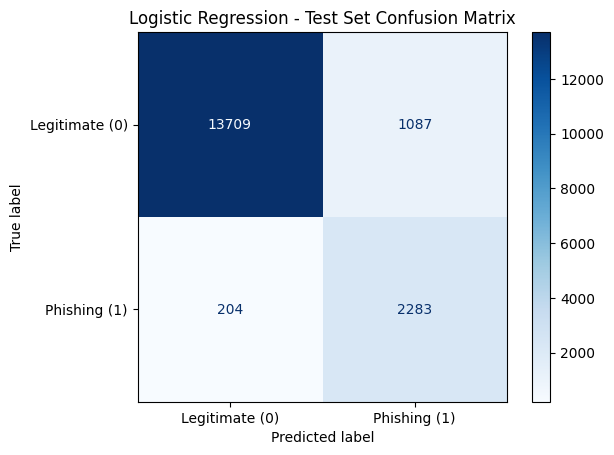


Decision Tree
[[14489   307]
 [  273  2214]]


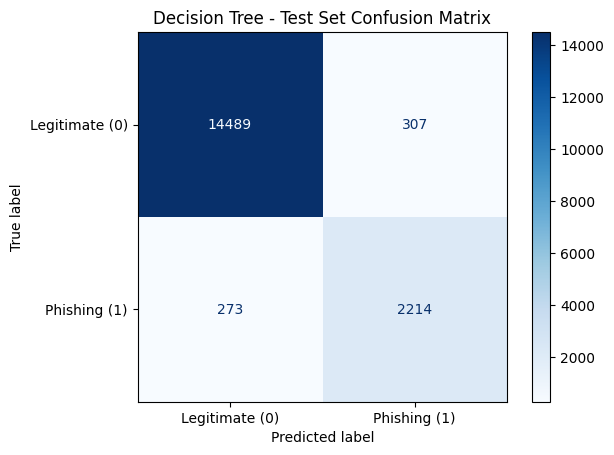


Random Forest
[[14663   133]
 [  258  2229]]


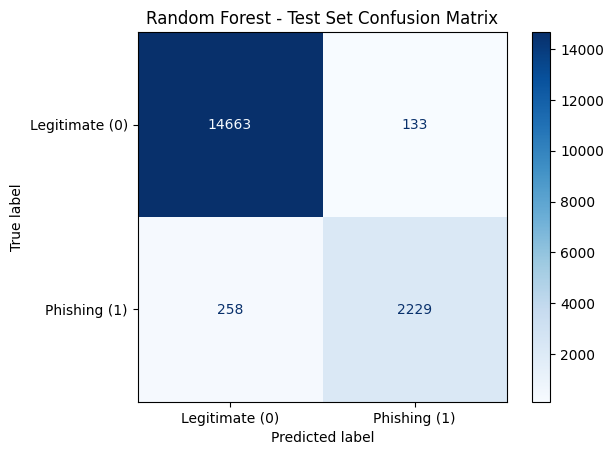


Linear SVM
[[13699  1097]
 [  206  2281]]


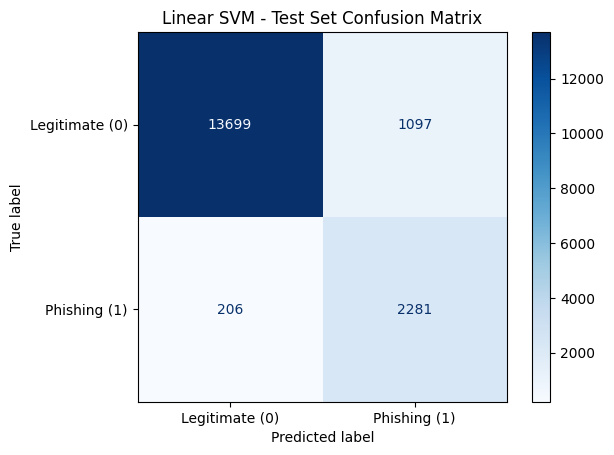

In [114]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, y_pred in test_predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Legitimate (0)", "Phishing (1)"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"{name} - Test Set Confusion Matrix")
    plt.show()

## 9. Implications for Cybersecurity Risk Management

The results demonstrate that superior overall classification performance does not necessarily minimise every cybersecurity risk. Random Forest achieved the highest F1-score (0.9194) and generated only 133 false positives, compared with 1,087 for Logistic Regression. However, Random Forest missed 258 phishing URLs, whereas Logistic Regression missed 204. Thus, Random Forest reduced false positives by 87.8% but increased missed phishing detections by 26.5% relative to Logistic Regression.

This trade-off has direct implications for organisational risk management. Random Forest may be preferable where excessive false alerts create substantial operational costs, whereas Logistic Regression may be more appropriate when minimising undetected phishing threats is prioritised. Nevertheless, these conclusions depend on the relative financial and security consequences of classification errors, which were not quantified in this study.

Feature importance findings further suggest that URL length, entropy and domain-related characteristics can support risk-based URL screening. However, their predictive contribution does not establish that these characteristics independently indicate malicious activity.

In relation to NIST CSF 2.0 and ISO/IEC 27005:2022, the findings support evidence-informed detection and risk treatment decisions. However, model performance was assessed using a held-out dataset rather than live organisational traffic. Consequently, operational deployment would require further assessment of alert-handling costs, changing phishing patterns and detection performance under real-world conditions.